### Notebook 4a — Image Cache for the Classification Experiments

> Resizes every image used in the classification notebooks once (real training, validation and test images, and the final synthetic images of both generators) to 224 × 224 with the same Lanczos pipeline, and stores them as compact `.npy` arrays. The training notebooks then load arrays from disk instead of decoding 50,000 large PNG files for every run.

**Inputs to attach** (+ Add Input): the NIH ChestX-ray14 dataset, the output of Notebook 2 (splits), the output of Notebook 3c (final manifest and DC-GAN images) and the outputs of the two Notebook 3b runs (RoentGen-v2 images, `pos` and `neg`).

**Output** (`/kaggle/working/cache`): `real_10k`, `val_full`, `test_full`, `dcgan` and `roentgen`, each as `<name>.npy` (uint8, N × 224 × 224) plus `<name>_index.csv` with the rows in the same order. `real_5k` is the subset of `real_10k` with `in_5k = True`; `clean` marks the images that belong to the clean version of the validation and test sets.

### 1. Configuration and Input Discovery

In [1]:
import os, time, math
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

SIZE = 224
INPUT_ROOT, CACHE = '/kaggle/input', Path('/kaggle/working/cache')
CACHE.mkdir(parents=True, exist_ok=True)
WORKERS = 8

ALL_FILES = []
for cur, dirs, files in os.walk(INPUT_ROOT):
    dirs[:] = [d for d in dirs if d != 'images']          # NIH image folders are not listed (their paths come from the CSV files)
    ALL_FILES += [os.path.join(cur, f) for f in files]
by_name = lambda nm: [p for p in ALL_FILES if os.path.basename(p) == nm]

h = by_name('real_10k.csv');                  assert h, 'real_10k.csv not found: attach the output of Notebook 2'
SPLITS_DIR = os.path.dirname(h[0])
h = by_name('synthetic_final_manifest.csv');  assert h, 'synthetic_final_manifest.csv not found: attach the output of Notebook 3c'
MANIFEST = h[0]
PNG = {os.path.basename(p): p for p in ALL_FILES if p.endswith('.png')}
print('SPLITS_DIR =', SPLITS_DIR); print('MANIFEST   =', MANIFEST); print(f'{len(PNG):,} synthetic PNG files found')

SPLITS_DIR = /kaggle/input/notebooks/anafarr/02-cohort-definition-and-splits/splits
MANIFEST   = /kaggle/input/notebooks/anafarr/03c-quality-final-dataset/synthetic_final_manifest.csv
15,005 synthetic PNG files found


### 2. Real Images

Every image is converted to grayscale and resized with Lanczos to 224 × 224 (the same pipeline used for the quality metrics in Notebook 3c). The 5K training set is a subset of the 10K one, so only the 10K set is stored.

In [2]:
def load_real(p):
    return np.asarray(Image.open(p).convert('L').resize((SIZE, SIZE), Image.Resampling.LANCZOS), dtype=np.uint8)

def cache_array(name, paths):
    paths = list(paths); arr = np.lib.format.open_memmap(CACHE / f'{name}.npy', mode='w+', dtype=np.uint8, shape=(len(paths), SIZE, SIZE))
    t0 = time.time(); step = 2000
    with ThreadPoolExecutor(WORKERS) as ex:
        for i in range(0, len(paths), step):
            arr[i:i + step] = np.stack(list(ex.map(load_real, paths[i:i + step])))
            print(f'  {name}: {min(i + step, len(paths)):,}/{len(paths):,}  ({time.time() - t0:.0f} s)', end='\r')
    arr.flush(); print(f'\n{name}: {arr.shape} saved ({time.time() - t0:.0f} s)'); return arr

r5, r10 = pd.read_csv(f'{SPLITS_DIR}/real_5k.csv'), pd.read_csv(f'{SPLITS_DIR}/real_10k.csv')
assert set(r5['image']) <= set(r10['image']), 'real_5k must be a subset of real_10k'
r10['in_5k'] = r10['image'].isin(set(r5['image']))
vf, vc = pd.read_csv(f'{SPLITS_DIR}/real_val_full.csv'), pd.read_csv(f'{SPLITS_DIR}/real_val_clean.csv')
tf, tc = pd.read_csv(f'{SPLITS_DIR}/real_test_full.csv'), pd.read_csv(f'{SPLITS_DIR}/real_test_clean.csv')
vf['clean'] = vf['image'].isin(set(vc['image'])); tf['clean'] = tf['image'].isin(set(tc['image']))
assert not (set(r10['Patient ID']) & set(vf['Patient ID'])) and not (set(r10['Patient ID']) & set(tf['Patient ID'])) and not (set(vf['Patient ID']) & set(tf['Patient ID'])), 'patient leakage between splits'
for d in (r10, vf, tf): assert set(d['label'].unique()) <= {0, 1}, 'unexpected labels'
print(f"real_10k {len(r10):,} (5K subset {int(r10.in_5k.sum()):,}) | val_full {len(vf):,} (clean {int(vf.clean.sum()):,}) | test_full {len(tf):,} (clean {int(tf.clean.sum()):,})")

for name, d in [('real_10k', r10), ('val_full', vf), ('test_full', tf)]:
    assert os.path.exists(d['path'].iloc[0]), 'NIH image path not found: attach the ChestX-ray14 dataset as input'
    cache_array(name, d['path']); d.to_csv(CACHE / f'{name}_index.csv', index=False)

real_10k 10,000 (5K subset 5,000) | val_full 15,100 (clean 8,915) | test_full 25,592 (clean 10,415)
  real_10k: 10,000/10,000  (94 s)
real_10k: (10000, 224, 224) saved (95 s)
  val_full: 15,100/15,100  (146 s)
val_full: (15100, 224, 224) saved (147 s)
  test_full: 25,592/25,592  (243 s)
test_full: (25592, 224, 224) saved (243 s)


### 3. Synthetic Images

The final manifest from Notebook 3c lists the 7,500 images of each generator (5,000 pneumonia, 2,500 No Finding). The DC-GAN images (128 px) and the RoentGen-v2 images (512 px) go through the same Lanczos resize to 224 × 224.

In [3]:
man = pd.read_csv(MANIFEST); man = man[~man['degenerate'].astype(bool)].copy()
man['index'] = man['image'].str.extract(r'_(\d+)\.png')[0].astype(int)
for g, gname in [('dcgan', 'dcgan'), ('roentgen_v2', 'roentgen')]:
    d = man[man.generator == g].sort_values(['label', 'index'], ascending=[False, True]).reset_index(drop=True)
    d['path'] = d['image'].map(PNG); assert d['path'].notna().all(), f'{int(d.path.isna().sum())} {g} PNG files not found: attach the missing outputs'
    assert (d.label == 1).sum() == 5000 and (d.label == 0).sum() == 2500, f'unexpected image counts for {g}: {d.label.value_counts().to_dict()}'
    cache_array(gname, d['path'])
    d[['image', 'label', 'generator', 'subset', 'index', 'source', 'checkpoint']].to_csv(CACHE / f'{gname}_index.csv', index=False)
    print(d.groupby(['label', 'subset']).size().rename('images').to_string(), '\n')

  dcgan: 7,500/7,500  (7 s)
dcgan: (7500, 224, 224) saved (9 s)
label  subset   
0      only_2500    2500
1      extra_pos    2500
       only_2500    2500 

  roentgen: 7,500/7,500  (23 s)
roentgen: (7500, 224, 224) saved (24 s)
label  subset   
0      only_2500    2500
1      extra_pos    2500
       only_2500    2500 



### 4. Check

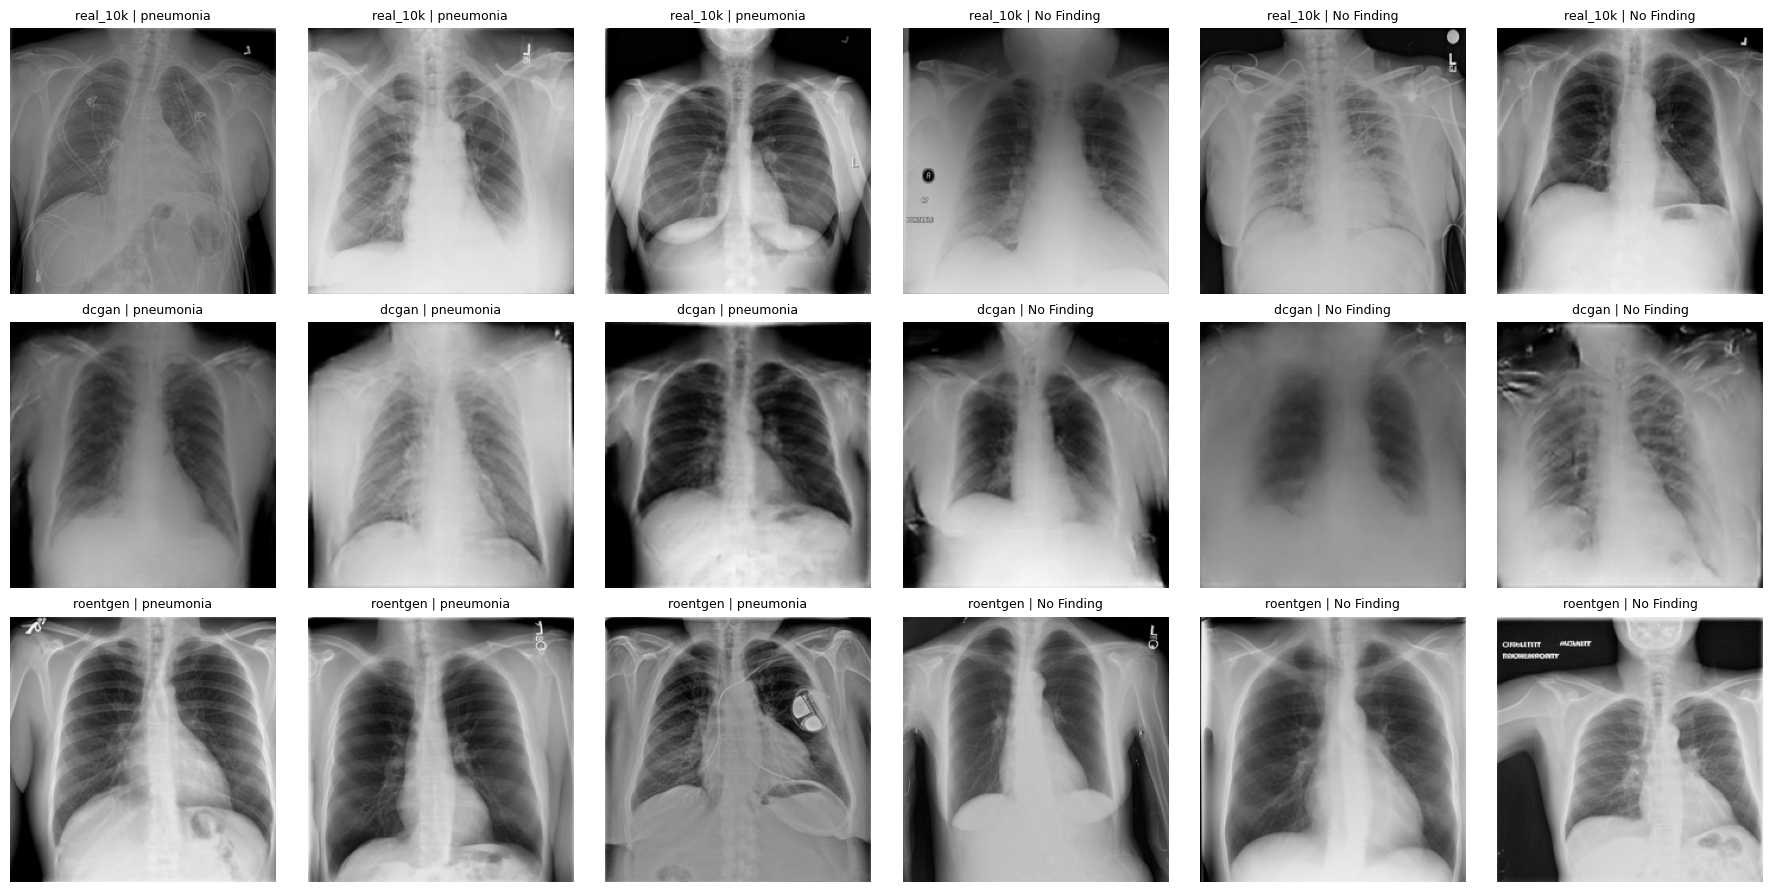

dcgan.npy                        376.3 MB
dcgan_index.csv                    0.5 MB
real_10k.npy                     501.8 MB
real_10k_index.csv                 1.5 MB
roentgen.npy                     376.3 MB
roentgen_index.csv                 0.6 MB
test_full.npy                   1284.1 MB
test_full_index.csv                4.1 MB
val_full.npy                     757.7 MB
val_full_index.csv                 2.3 MB
total 3.31 GB


In [4]:
fig, ax = plt.subplots(3, 6, figsize=(18, 9))
for r_, (name, idxf) in enumerate([('real_10k', 'real_10k'), ('dcgan', 'dcgan'), ('roentgen', 'roentgen')]):
    a, d = np.load(CACHE / f'{name}.npy', mmap_mode='r'), pd.read_csv(CACHE / f'{idxf}_index.csv')
    pick = list(d[d.label == 1].index[:3]) + list(d[d.label == 0].index[:3])
    for c_, i in enumerate(pick):
        ax[r_, c_].imshow(a[i], cmap='gray', vmin=0, vmax=255); ax[r_, c_].set_title(f"{name} | {'pneumonia' if d.label[i] else 'No Finding'}", fontsize=9); ax[r_, c_].axis('off')
plt.tight_layout(); plt.show()
tot = 0
for p in sorted(CACHE.glob('*')): sz = p.stat().st_size / 1e6; tot += sz; print(f'{p.name:28s} {sz:9.1f} MB')
print(f'total {tot / 1000:.2f} GB')